# Thư Viện

In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Thiết lập Seed tái lập kết quả

In [2]:
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Tải bộ dữ liệu Fashion-MNIST và khai báo tên lớp

In [3]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


# Chia tập Validation và chuẩn hóa dữ liệu

In [4]:
X_val = X_train_full[:10000]
y_val = y_train_full[:10000]
X_train = X_train_full[10000:]
y_train = y_train_full[10000:]

X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Tạo pipeline

In [5]:
BATCH_SIZE = 64

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train), seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Xây dựng, biên dịch và huấn luyện mô hình gốc (Baseline MLP)

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_mlp_fashion.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40


c:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8215 - loss: 0.5022 - val_accuracy: 0.8407 - val_loss: 0.4216
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8659 - loss: 0.3696 - val_accuracy: 0.8704 - val_loss: 0.3516
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8777 - loss: 0.3358 - val_accuracy: 0.8755 - val_loss: 0.3416
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8875 - loss: 0.3073 - val_accuracy: 0.8620 - val_loss: 0.3678
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8919 - loss: 0.2896 - val_accuracy: 0.8811 - val_loss: 0.3209
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8963 - loss: 0.2762 - val_accuracy: 0.8839 - val_loss: 0.3079
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9018 - loss: 0.2624 - val_accuracy: 0.8899 - val_loss: 0.3000
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9059 - loss: 0.2483 - val_accuracy: 0.8863 - val_

# Đánh giá mô hình gốc trên tập Test và vẽ đường cong Loss

Baseline Test loss: 0.3390 - Test accuracy: 0.8868


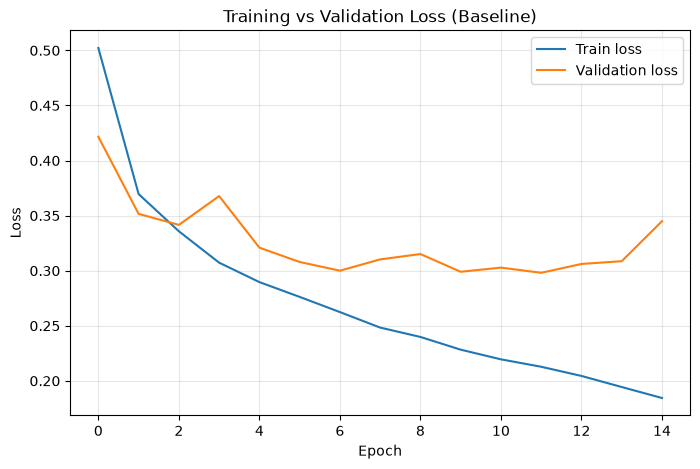

In [7]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Baseline Test loss: {test_loss:.4f} - Test accuracy: {test_acc:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss (Baseline)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# BÀI 1 : Thay đổi kiến trúc

In [8]:
architectures = {
    "1 hidden layer (256)": [
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ],
    "2 hidden layers (256-128)": [
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ],
    "3 hidden layers (256-128-64)": [
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ]
}

results_b1 = []

for name, layers in architectures.items():
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    m = tf.keras.Sequential(layers)
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    cb = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]

    start_time = time.time()
    hist = m.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=cb,
        verbose=0
    )
    train_time = time.time() - start_time

    val_loss, val_acc = m.evaluate(val_ds, verbose=0)
    test_loss, test_acc = m.evaluate(test_ds, verbose=0)

    results_b1.append({
        "Architecture": name,
        "Parameters": m.count_params(),
        "Epochs Run": len(hist.history["loss"]),
        "Train Time (s)": round(train_time, 2),
        "Val Accuracy": round(val_acc, 4),
        "Test Accuracy": round(test_acc, 4)
    })

df_b1 = pd.DataFrame(results_b1)
display(df_b1)

,Architecture,Parameters,Epochs Run,Train Time (s),Val Accuracy,Test Accuracy
0,1 hidden layer (256),203530,11,24.85,0.8900,0.8837
1,2 hidden layers (256-128),235146,10,26.40,0.8907,0.8808
2,3 hidden layers (256-128-64),242762,12,32.84,0.8940,0.8805


Nhận xét:
* Số lượng tham số (Parameters): Tăng dần theo độ sâu của mạng, lần lượt từ 203,530 (1 lớp ẩn) lên 235,146 (2 lớp ẩn) và 242,762 (3 lớp ẩn). Phần lớn tham số tập trung ở lớp ẩn đầu tiên do kết nối trực tiếp từ vector ảnh đầu vào $784$ chiều.   
* Thời gian huấn luyện (Train Time): Tăng dần từ 24.85s lên 26.40s và 32.84s. Mô hình 3 lớp ẩn tốn nhiều thời gian nhất do khối lượng tính toán mỗi bước lớn hơn và số epoch thực tế chạy nhiều hơn (12 epoch so với 11 và 10 epoch).   
* Độ chính xác (Val Accuracy và Test Accuracy):
     * Val Accuracy tăng nhẹ khi bổ sung thêm tầng ẩn, đạt 0.8900 ở 1 lớp, 0.8907 ở 2 lớp và cao nhất 0.8940 ở mô hình 3 lớp ẩn.  
     * Ngược lại, Test Accuracy đạt đỉnh ngay ở cấu trúc đơn giản nhất 1 hidden layer (256) với 0.8837, sau đó giảm nhẹ xuống 0.8808 (2 lớp) và 0.8805 (3 lớp). Đồng thời, mức chênh lệch giữa Val Accuracy và Test Accuracy nới rộng từ 0.0063 lên 0.0135, cho thấy mô hình nhiều tầng bắt đầu xuất hiện dấu hiệu học khớp quá mức (overfitting) nhẹ.   

# Bài 2. Thử learning rate

c:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


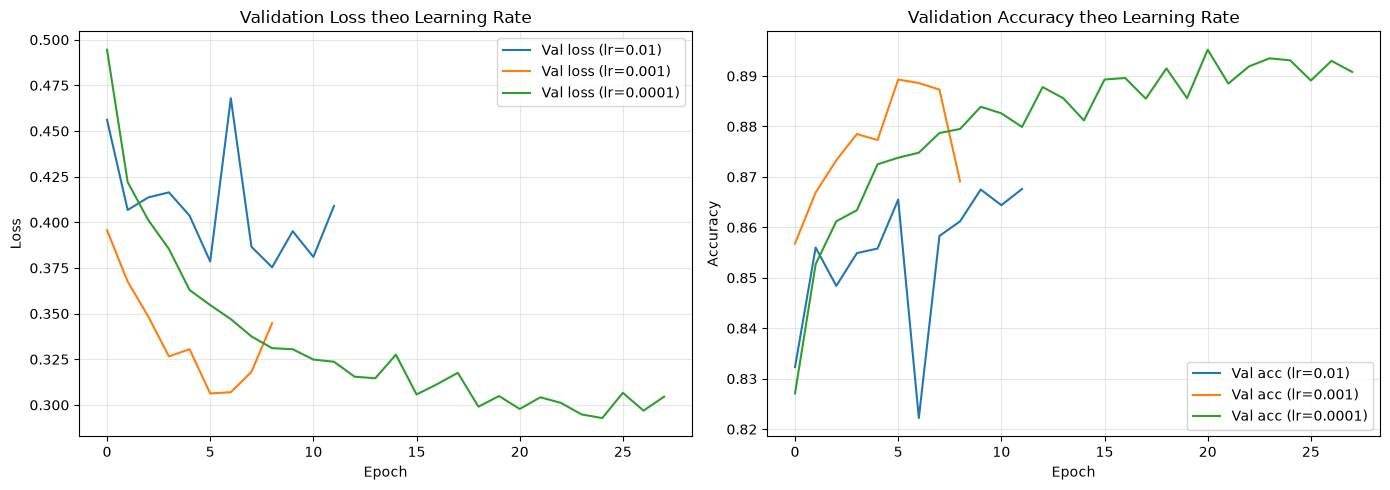

In [9]:
learning_rates = [1e-2, 1e-3, 1e-4]
histories_b2 = {}

for lr in learning_rates:
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    m = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    cb = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]

    hist = m.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=cb,
        verbose=0
    )
    histories_b2[lr] = hist

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for lr, hist in histories_b2.items():
    axes[0].plot(hist.history["val_loss"], label=f"Val loss (lr={lr})")
    axes[1].plot(hist.history["val_accuracy"], label=f"Val acc (lr={lr})")

axes[0].set_title("Validation Loss theo Learning Rate")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation Accuracy theo Learning Rate")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Nhận xét:
* lr = 0.01 (1e-2 — xanh dương): Tốc độ học quá lớn làm bước cập nhật trọng số dao động mạnh (val_loss vọt lên 0.468, val_accuracy tụt xuống 82.2% ở epoch 6) và dừng tại epoch 11 với độ chính xác tối đa chỉ đạt khoảng 86.8%.
* lr = 0.001 (1e-3 — cam): Mô hình hội tụ nhanh nhất, đạt đáy val_loss (~0.306) và val_accuracy (~88.9%) ngay tại epoch 5, sau đó bắt đầu overfitting và dừng huấn luyện ở epoch 8.   
* lr = 0.0001 (1e-4 — xanh lá): Bước nhảy nhỏ nên hội tụ chậm nhưng ổn định nhất, đạt val_accuracy cao nhất (~89.5% tại epoch 20) và val_loss thấp nhất (~0.294 tại epoch 24) trước khi dừng ở epoch 27.   
* Mức lr = 1e-3 cho sự cân bằng tốt nhất giữa tốc độ hội tụ và hiệu năng, trong khi lr = 1e-4 đạt độ chính xác validation cao hơn nhẹ nhưng cần số epoch huấn luyện gấp hơn 3 lần.   

# Bài 3. Thử batch size

In [10]:
batch_sizes = [32, 128, 512]
results_b3 = []

for bs in batch_sizes:
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    train_ds_bs = (
        tf.data.Dataset.from_tensor_slices((X_train, y_train))
        .shuffle(buffer_size=len(X_train), seed=SEED)
        .batch(bs)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds_bs = (
        tf.data.Dataset.from_tensor_slices((X_val, y_val))
        .batch(bs)
        .prefetch(tf.data.AUTOTUNE)
    )
    test_ds_bs = (
        tf.data.Dataset.from_tensor_slices((X_test, y_test))
        .batch(bs)
        .prefetch(tf.data.AUTOTUNE)
    )

    m = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    cb = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]

    start_time = time.time()
    hist = m.fit(
        train_ds_bs,
        validation_data=val_ds_bs,
        epochs=40,
        callbacks=cb,
        verbose=0
    )
    train_time = time.time() - start_time
    epochs_run = len(hist.history["loss"])

    val_loss, val_acc = m.evaluate(val_ds_bs, verbose=0)
    test_loss, test_acc = m.evaluate(test_ds_bs, verbose=0)

    results_b3.append({
        "Batch Size": bs,
        "Epochs Run": epochs_run,
        "Total Time (s)": round(train_time, 2),
        "Time/Epoch (s)": round(train_time / epochs_run, 2),
        "Val Accuracy": round(val_acc, 4),
        "Test Accuracy": round(test_acc, 4)
    })

df_b3 = pd.DataFrame(results_b3)
display(df_b3)

,Batch Size,Epochs Run,Total Time (s),Time/Epoch (s),Val Accuracy,Test Accuracy
0,32,9,35.79,3.98,0.8882,0.8760
1,128,13,19.67,1.51,0.8925,0.8840
2,512,19,13.47,0.71,0.8971,0.8909


Nhận xét :
* Tốc độ huấn luyện (Time/Epoch và Total Time): Khi tăng kích thước batch từ 32 lên 128 và 512, thời gian chạy trung bình mỗi epoch giảm mạnh từ 3.98s xuống 1.51s và chỉ còn 0.71s (nhanh hơn gấp 5.6 lần). Nguyên nhân là batch lớn làm giảm số lần cập nhật trọng số trong một epoch và tận dụng tốt hơn khả năng tính toán song song của phần cứng. Nhờ đó, dù số epoch cần để hội tụ tăng từ 9 lên 13 và 19 epoch, tổng thời gian huấn luyện (Total Time) vẫn giảm đáng kể từ 35.79s xuống 19.67s và 13.47s.   
* Độ chính xác (Val Accuracy và Test Accuracy): Cả hai chỉ số đều cải thiện đều đặn khi tăng Batch Size. Ở mức batch_size = 32, nhiễu gradient từ các batch nhỏ làm dao động quá trình học và kích hoạt dừng sớm ở epoch 9, cho kết quả thấp nhất (Val Accuracy = 0.8882, Test Accuracy = 0.8760). Mức batch_size = 128 cải thiện lên Val Accuracy = 0.8925 và Test Accuracy = 0.8840. Mức batch_size = 512 tạo ra ước lượng gradient ổn định nhất, giúp mô hình huấn luyện tới epoch 19 và đạt kết quả cao nhất với Val Accuracy = 0.8971 cùng Test Accuracy = 0.8909.   
* Trong thí nghiệm này, batch_size = 512 là lựa chọn tối ưu toàn diện nhất khi vừa rút ngắn tổng thời gian huấn luyện xuống mức thấp nhất (13.47s), vừa đạt độ chính xác cao nhất trên tập Test (89.09%) với mức chênh lệch Val - Test nhỏ nhất (0.62%).   

# Bài 4. Thêm Dropout

Epoch 1/40


c:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7805 - loss: 0.6098 - val_accuracy: 0.8393 - val_loss: 0.4399
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8413 - loss: 0.4414 - val_accuracy: 0.8655 - val_loss: 0.3660
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8507 - loss: 0.4041 - val_accuracy: 0.8713 - val_loss: 0.3601
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8600 - loss: 0.3813 - val_accuracy: 0.8749 - val_loss: 0.3380
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8667 - loss: 0.3646 - val_accuracy: 0.8796 - val_loss: 0.3355
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8714 - loss: 0.3483 - val_accuracy: 0.8715 - val_loss: 0.3460
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8726 - loss: 0.3424 - val_accuracy: 0.8799 - val_loss: 0.3288
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8786 - loss: 0.3306 - val_accuracy: 0.8808 - val_

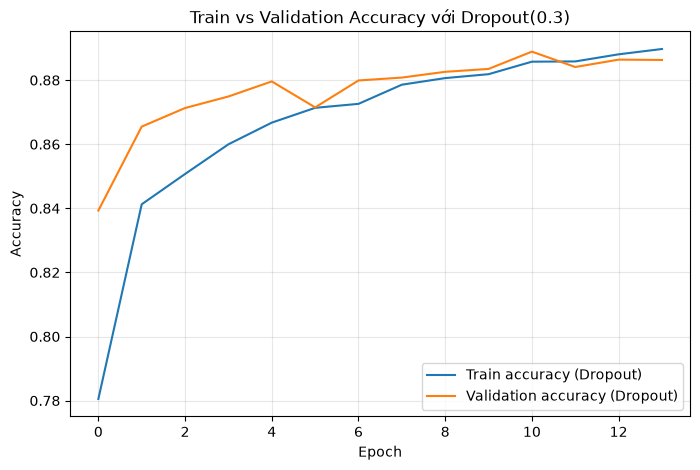

In [11]:
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

model_dropout = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_dropout.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_dropout = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

history_dropout = model_dropout.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_dropout,
    verbose=1
)

test_loss_do, test_acc_do = model_dropout.evaluate(test_ds, verbose=0)
print(f"Test accuracy (Dropout 0.3): {test_acc_do:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(history_dropout.history["accuracy"], label="Train accuracy (Dropout)")
plt.plot(history_dropout.history["val_accuracy"], label="Validation accuracy (Dropout)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Train vs Validation Accuracy với Dropout(0.3)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Nhận xét :
* Giai đoạn đầu huấn luyện (Epoch 0 – 10): Đường Validation accuracy (màu cam) nằm cao hơn đường Train accuracy (màu xanh dương) trong suốt 10 epoch đầu tiên, cụ thể tại epoch 0 đạt khoảng 0.839 so với 0.781 của tập train. Điều này đúng với bản chất của Dropout(0.3) vì 30% số nơ-ron bị tắt ngẫu nhiên trong quá trình huấn luyện, trong khi lúc đánh giá trên tập validation toàn bộ 100% nơ-ron đều được sử dụng.   
* Quá trình hội tụ: Cả hai đường cong tăng trưởng đều đặn, bám sát nhau và đạt trạng thái tối ưu tại epoch 10 với Validation accuracy chạm đỉnh khoảng 0.889 (88.9%) cùng Train accuracy đạt khoảng 0.885.   
* Khả năng kiểm soát Overfitting (Epoch 11 – 13): Từ epoch 11 trở đi, Train accuracy mới bắt đầu vượt nhẹ lên trên Validation accuracy trước khi cơ chế dừng sớm ngắt huấn luyện tại epoch 13. Khoảng cách chênh lệch cuối cùng giữa hai đường rất nhỏ, chỉ vào khoảng 0.003 (~0.8895 trên tập train so với ~0.886 trên tập validation).   
* Việc bổ sung Dropout(0.3) sau các tầng ẩn đã triệt tiêu gần như hoàn toàn hiện tượng học vẹt (overfitting), giúp mô hình duy trì sự đồng nhất cao giữa khả năng học trên tập huấn luyện và khả năng tổng quát hóa trên dữ liệu mới.   

# Bài 5. Thêm L2 regularization

In [12]:
l2_values = [1e-4, 1e-3]
results_b5 = []

for reg_val in l2_values:
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    m = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(
            256,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(reg_val)
        ),
        tf.keras.layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(reg_val)
        ),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    cb = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]

    hist = m.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=cb,
        verbose=0
    )

    best_ep = np.argmin(hist.history["val_loss"])
    train_acc_best = hist.history["accuracy"][best_ep]
    val_loss, val_acc = m.evaluate(val_ds, verbose=0)
    test_loss, test_acc = m.evaluate(test_ds, verbose=0)

    results_b5.append({
        "L2 Lambda": reg_val,
        "Best Epoch": best_ep + 1,
        "Train Acc": round(train_acc_best, 4),
        "Val Acc": round(val_acc, 4),
        "Gap (Train - Val)": round(train_acc_best - val_acc, 4),
        "Test Acc": round(test_acc, 4)
    })

df_b5 = pd.DataFrame(results_b5)
display(df_b5)

,L2 Lambda,Best Epoch,Train Acc,Val Acc,Gap (Train - Val),Test Acc
0,0.0001,9,0.9005,0.8909,0.0096,0.8823
1,0.0010,14,0.8854,0.8837,0.0017,0.8737


Nhận xét :
* Với L2 Lambda = 0.0001 (1e-4):Mô hình đạt trạng thái tối ưu sớm tại Best Epoch = 9 với Train Acc = 0.9005 và Val Acc = 0.8909.   
* Mức chênh lệch Gap (Train - Val) chỉ còn 0.0096 (0.96%), giúp kiểm soát tốt hiện tượng overfitting và đạt độ chính xác trên tập kiểm tra là Test Acc = 0.8823 (88.23%).   
* Với L2 Lambda = 0.0010 (1e-3):Khi tăng hệ số phạt lên gấp 10 lần, mô hình hội tụ chậm hơn (Best Epoch = 14) và triệt tiêu gần như hoàn toàn độ lệch giữa hai tập với Gap (Train - Val) giảm xuống chỉ còn 0.0017 (0.17%).   
* Tuy nhiên, hệ số phạt L2 lớn làm kìm hãm độ lớn trọng số quá mức (dấu hiệu underfitting nhẹ), kéo theo cả Train Acc (0.8854), Val Acc (0.8837) và Test Acc (0.8737) đều giảm so với mức 0.0001.   
* Trong hai cấu hình thử nghiệm, L2 Lambda = 0.0001 mang lại hiệu quả cân bằng tốt nhất khi vừa giữ Gap dưới 1%, vừa đạt độ chính xác cao nhất trên tập Validation (89.09%) và tập Test (88.23%).   

# Bài 6. Phân tích lỗi

Test loss: 0.3390 - Test accuracy: 0.8868


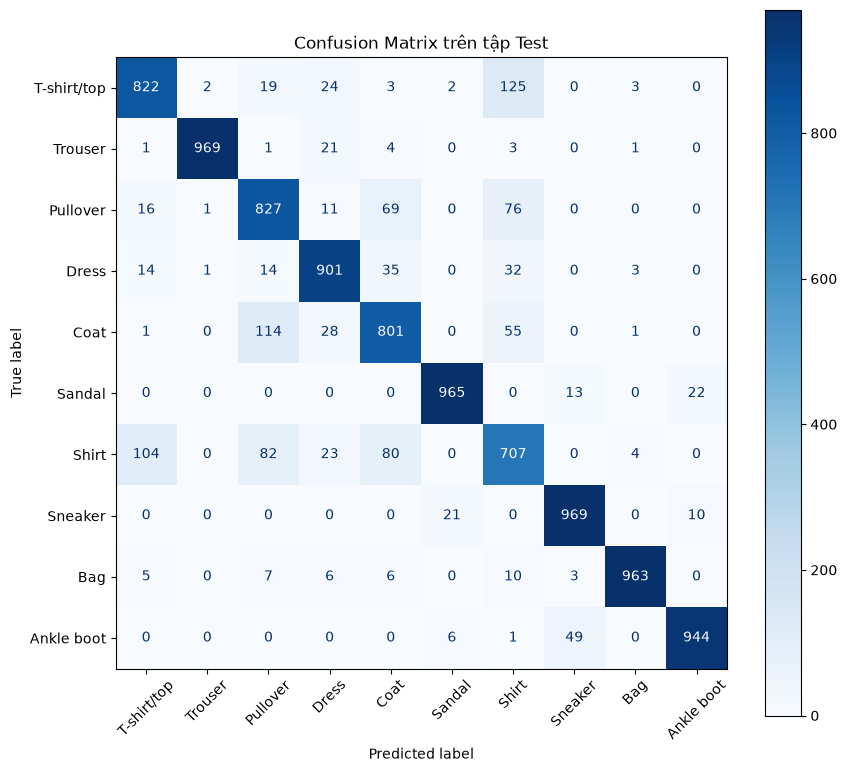

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.82      0.84      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.78      0.83      0.80      1000
       Dress       0.89      0.90      0.89      1000
        Coat       0.80      0.80      0.80      1000
      Sandal       0.97      0.96      0.97      1000
       Shirt       0.70      0.71      0.70      1000
     Sneaker       0.94      0.97      0.95      1000
         Bag       0.99      0.96      0.98      1000
  Ankle boot       0.97      0.94      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000

Tổng số mẫu dự đoán sai: 1132 / 10000


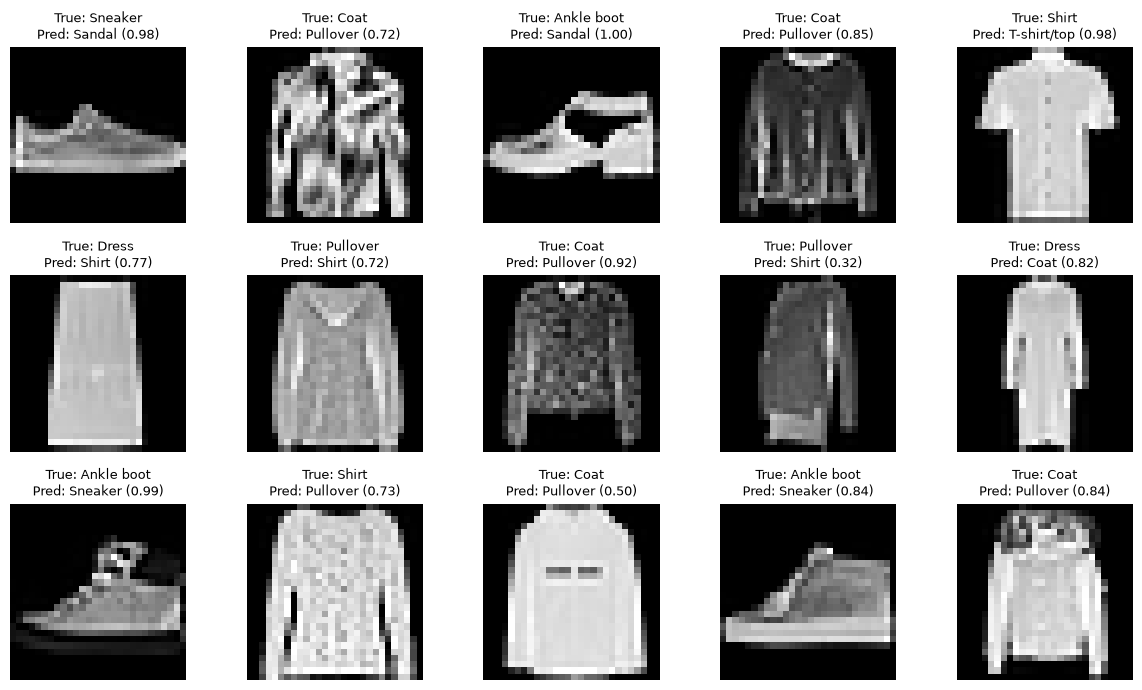

In [13]:
best_model = tf.keras.models.load_model("best_mlp_fashion.keras")

test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f} - Test accuracy: {test_acc:.4f}")

y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", xticks_rotation=45, ax=ax)
plt.title("Confusion Matrix trên tập Test")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=class_names))

misclassified_idx = np.where(y_pred != y_test)[0]
print(f"Tổng số mẫu dự đoán sai: {len(misclassified_idx)} / {len(y_test)}")

fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for i, ax in enumerate(axes.ravel()):
    idx = misclassified_idx[i]
    true_label = class_names[y_test[idx]]
    pred_label = class_names[y_pred[idx]]
    conf = y_pred_probs[idx][y_pred[idx]]

    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(f"True: {true_label}\nPred: {pred_label} ({conf:.2f})", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

Nhận xét : 
* Hiệu năng tổng quát: Mô hình đạt Test accuracy = 88.68% (Test loss = 0.3390), dự đoán sai 1,132 / 10,000 mẫu kiểm tra.   
* Nhóm phân loại tốt (F1-score từ 0.95 – 0.98): Các lớp có hình dáng đặc trưng như Trouser (0.98), Bag (0.98), Sandal (0.97), Ankle boot (0.96) và Sneaker (0.95) được tách biệt rất rõ ràng.   
* Nhóm hay nhầm lẫn nhất: Shirt đạt hiệu năng thấp nhất (F1 = 0.70, chỉ đúng 707/1000 mẫu) do bị nhầm lẫn mạnh sang T-shirt/top (104 mẫu), Pullover (82 mẫu) và Coat (80 mẫu). Tương tự, T-shirt/top cũng bị đoán nhầm thành Shirt (125 mẫu) và Coat nhầm thành Pullover (114 mẫu).   
* Nguyên nhân cốt lõi: Nhiều ảnh có đường viền tổng thể giống nhau bị đoán sai với độ tự tin rất cao (ví dụ Shirt ngắn tay bị đoán nhầm thành T-shirt/top với xác suất 0.98). Do lớp Flatten() làm mất cấu trúc không gian 2D cục bộ (cổ áo, hàng cúc, chất liệu vải), cần chuyển sang kiến trúc mạng tích chập (CNN) để cải thiện khả năng phân biệt nhóm áo thân trên.   